姓名：李晨辉　　学号：2026009793　　日期：2026-11-11

# 03｜自主实验：学习率对 CNN 训练的影响

这个 Notebook 做了三组学习率对照（1e-4、1e-3、1e-2），除学习率外其它条件保持一致。
开发阶段只用训练集和验证集，三组结果都保留了下来，包括和预期不一致的部分。测试集留到最后（04）统一评估。

## 1. 加载数据与公共训练函数

In [1]:
from pathlib import Path
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 128
EPOCHS = 5
LEARNING_RATE = 1e-3
NUM_WORKERS = 0  # 对初学者和 Windows 环境更稳妥
DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

transform = transforms.ToTensor()
full_train_dataset = datasets.FashionMNIST(
    root=str(DATA_DIR), train=True, download=True, transform=transform
)
test_dataset = datasets.FashionMNIST(
    root=str(DATA_DIR), train=False, download=True, transform=transform
)
train_dataset, val_dataset = random_split(
    full_train_dataset,
    [55000, 5000],
    generator=torch.Generator().manual_seed(SEED)
)

def make_loaders(seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, generator=generator
    )
    val_loader = DataLoader(
        val_dataset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS
    )
    return train_loader, val_loader

train_loader, val_loader = make_loaders()
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS
)

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]
print(f"训练集: {len(train_dataset)} | 验证集: {len(val_dataset)} | 测试集: {len(test_dataset)}")
print("注意：本 Notebook 只使用训练集和验证集进行开发；测试集留到最终验收时再使用。")


Device: cpu
训练集: 55000 | 验证集: 5000 | 测试集: 10000
注意：本 Notebook 只使用训练集和验证集进行开发；测试集留到最终验收时再使用。


In [2]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None
    model.train() if is_training else model.eval()
    total_loss, total_correct, total_count = 0.0, 0, 0

    with torch.set_grad_enabled(is_training):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if is_training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = criterion(logits, labels)

            if is_training:
                loss.backward()
                optimizer.step()

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_count += batch_size

    return total_loss / total_count, 100.0 * total_correct / total_count


def fit_model(model, train_loader, val_loader, epochs, learning_rate, run_name):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = []

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion)
        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy_pct": train_acc,
            "val_loss": val_loss,
            "val_accuracy_pct": val_acc,
            "learning_rate": learning_rate,
        }
        history.append(row)
        print(
            f"[{run_name}] Epoch {epoch:02d}/{epochs} | "
            f"train loss={train_loss:.4f}, train acc={train_acc:.2f}% | "
            f"val loss={val_loss:.4f}, val acc={val_acc:.2f}%"
        )

    history_df = pd.DataFrame(history)
    history_df.to_csv(RESULTS_DIR / f"{run_name}_history.csv", index=False)
    metrics = {
        "run_name": run_name,
        "seed": SEED,
        "epochs": epochs,
        "learning_rate": learning_rate,
        "final_train_loss": float(history_df.iloc[-1]["train_loss"]),
        "final_train_accuracy_pct": float(history_df.iloc[-1]["train_accuracy_pct"]),
        "final_val_loss": float(history_df.iloc[-1]["val_loss"]),
        "final_val_accuracy_pct": float(history_df.iloc[-1]["val_accuracy_pct"]),
        "best_val_accuracy_pct": float(history_df["val_accuracy_pct"].max()),
        "device": str(device),
    }
    (RESULTS_DIR / f"{run_name}_metrics.json").write_text(
        json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    torch.save(model.state_dict(), RESULTS_DIR / f"{run_name}_state_dict.pt")
    return model, history_df, metrics


def plot_history(history_df, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train")
    axes[0].plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    axes[1].plot(history_df["epoch"], history_df["train_accuracy_pct"], marker="o", label="Train")
    axes[1].plot(history_df["epoch"], history_df["val_accuracy_pct"], marker="o", label="Validation")
    axes[1].set_title("Accuracy (%)")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f"{title.lower().replace(' ', '_')}_curves.png", dpi=150)
    plt.show()


### 补充：CNN 模型定义

这个 Notebook 里直接调用 CNN()，前面却没有给出类定义，独立运行会报 NameError: name 'CNN' is not defined。为了保证三组实验的结构和 02 里完全一致，在这里补上和 02 相同的 CNN 实现。

In [3]:
class CNN(nn.Module):
    def __init__(self, channels_1=32, channels_2=64, kernel_size=3):
        super().__init__()
        padding = kernel_size // 2
        self.features = nn.Sequential(
            nn.Conv2d(1, channels_1, kernel_size=kernel_size, padding=padding),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(channels_1, channels_2, kernel_size=kernel_size, padding=padding),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(channels_2 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


### 我的实验设计

**研究问题：** 数据划分、模型结构、batch size、优化器、训练轮数（3 轮）和随机种子都不变，只把学习率取 1e-4、1e-3、1e-2 时，CNN 前三轮的收敛过程和最终的验证集表现有什么区别？

**初始假设：** 3 轮预算不长，我猜 1e-3 会比较合适；1e-4 太小，3 轮内学得不够，验证指标应该最差；1e-2 前期损失掉得快，但可能震荡，最后不一定最好。

**自变量：** 学习率 `learning_rate`，1e-4 / 1e-3 / 1e-2，三个值差不多差一个数量级。

**因变量（观察指标）：** 每轮的训练损失、验证损失和两边准确率；重点看第 3 轮结束时的验证损失和验证准确率，以及前 3 轮验证损失下降的快慢。

**控制变量：** 划分（55,000 / 5,000，seed 42）、3 轮、batch 128、Adam、`CNN(32, 64, k=3)`、种子 42、不做数据增强。

**设计理由：** 学习率是训练里最常调、影响最直接的超参，改它只要一行，其它条件天然能保持一致；三个值差一个数量级，趋势应该比较明显。

**可能的混杂因素：** 只跑一个种子，初始化和数据顺序的随机性都在里面；只训 3 轮，反映的是短预算下的收敛，不代表训练充分之后的样子；每组重新建模型和 DataLoader，但种子相同，数据顺序一致；CPU 上算子实现差异可能带来很小的数值差别；不同学习率在同样轮数里“走的步数”不同，我比的是同样轮数下的表现。


In [4]:
# ===== 实验条件 =====
EXPERIMENT_NAME = "cnn_learning_rate_study"
EPOCHS_PER_RUN = 3

# 自变量：学习率。三个取值相隔一个数量级，分别代表偏小/默认/偏大。
EXPERIMENT_VALUES = [1e-4, 1e-3, 1e-2]

print("实验名称:", EXPERIMENT_NAME)
print("实验条件:", EXPERIMENT_VALUES)
print("每组训练轮数:", EPOCHS_PER_RUN)

实验名称: cnn_learning_rate_study
实验条件: [0.0001, 0.001, 0.01]
每组训练轮数: 3


## 3. 运行对照实验

三组使用相同的数据划分、相同训练轮数和固定随机种子，只有学习率不同，这样比较才是公平的。

In [5]:
experiment_rows = []

for value in EXPERIMENT_VALUES:
    set_seed(SEED)
    train_loader_run, val_loader_run = make_loaders(seed=SEED)
    model = CNN()
    model, history_df, metrics = fit_model(
        model=model,
        train_loader=train_loader_run,
        val_loader=val_loader_run,
        epochs=EPOCHS_PER_RUN,
        learning_rate=float(value),
        run_name=f"{EXPERIMENT_NAME}_{str(value).replace('.', 'p')}"
    )
    experiment_rows.append({
        "experiment_name": EXPERIMENT_NAME,
        "independent_variable": "learning_rate",
        "condition": value,
        "epochs": EPOCHS_PER_RUN,
        "seed": SEED,
        "final_train_loss": metrics["final_train_loss"],
        "final_train_accuracy_pct": metrics["final_train_accuracy_pct"],
        "final_val_loss": metrics["final_val_loss"],
        "final_val_accuracy_pct": metrics["final_val_accuracy_pct"],
        "best_val_accuracy_pct": metrics["best_val_accuracy_pct"],
    })

experiment_results = pd.DataFrame(experiment_rows)
experiment_results.to_csv(RESULTS_DIR / f"{EXPERIMENT_NAME}_summary.csv", index=False)
display(experiment_results)


[cnn_learning_rate_study_0p0001] Epoch 01/3 | train loss=0.9460, train acc=70.42% | val loss=0.5963, val acc=78.04%


[cnn_learning_rate_study_0p0001] Epoch 02/3 | train loss=0.5245, train acc=81.16% | val loss=0.5167, val acc=80.46%


[cnn_learning_rate_study_0p0001] Epoch 03/3 | train loss=0.4546, train acc=83.86% | val loss=0.4458, val acc=84.46%


[cnn_learning_rate_study_0p001] Epoch 01/3 | train loss=0.5394, train acc=80.77% | val loss=0.4053, val acc=85.40%


[cnn_learning_rate_study_0p001] Epoch 02/3 | train loss=0.3296, train acc=88.14% | val loss=0.3388, val acc=87.60%


[cnn_learning_rate_study_0p001] Epoch 03/3 | train loss=0.2809, train acc=89.74% | val loss=0.3032, val acc=89.04%


[cnn_learning_rate_study_0p01] Epoch 01/3 | train loss=0.4583, train acc=83.37% | val loss=0.3529, val acc=87.62%


[cnn_learning_rate_study_0p01] Epoch 02/3 | train loss=0.2956, train acc=89.18% | val loss=0.3406, val acc=87.66%


[cnn_learning_rate_study_0p01] Epoch 03/3 | train loss=0.2668, train acc=90.07% | val loss=0.3201, val acc=89.06%


,experiment_name,independent_variable,condition,epochs,seed,final_train_loss,final_train_accuracy_pct,final_val_loss,final_val_accuracy_pct,best_val_accuracy_pct
0,cnn_learning_rate_study,learning_rate,0.0001,3,42,0.454621,83.861818,0.445834,84.46,84.46
1,cnn_learning_rate_study,learning_rate,0.0010,3,42,0.280886,89.743636,0.303187,89.04,89.04
2,cnn_learning_rate_study,learning_rate,0.0100,3,42,0.266800,90.070909,0.320081,89.06,89.06


## 4. 可视化比较与初步解释

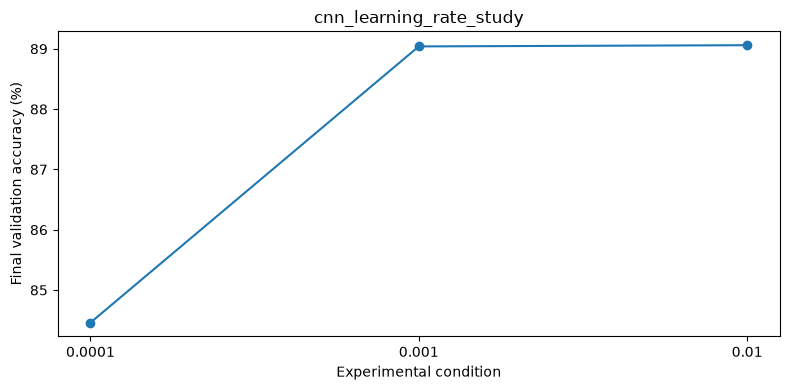

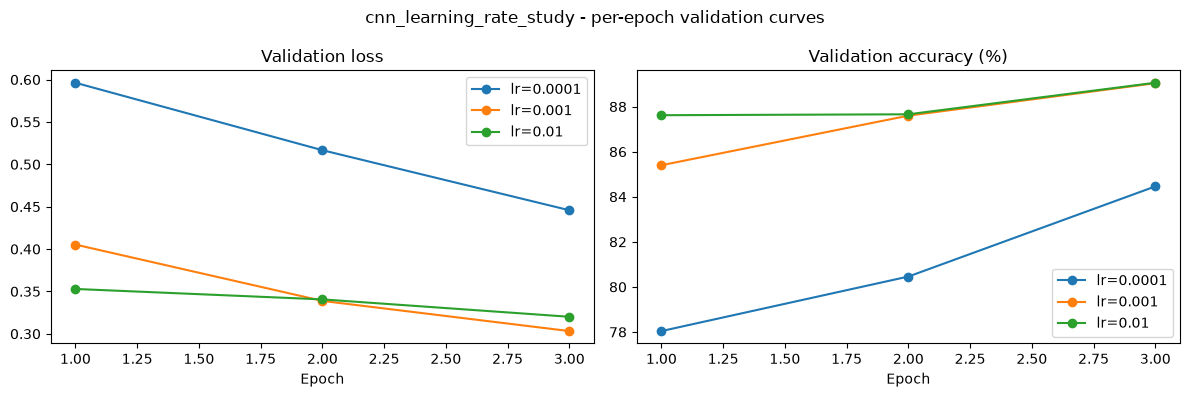

请结合训练曲线、验证损失与准确率解释结果。不要只根据单一指标下结论。


In [6]:
if "condition" in experiment_results.columns and len(experiment_results) >= 2:
    plt.figure(figsize=(8, 4))
    plt.plot(
        experiment_results["condition"].astype(str),
        experiment_results["final_val_accuracy_pct"],
        marker="o"
    )
    plt.xlabel("Experimental condition")
    plt.ylabel("Final validation accuracy (%)")
    plt.title(EXPERIMENT_NAME)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"{EXPERIMENT_NAME}_comparison.png", dpi=150)
    plt.show()

# 把三组条件的逐轮验证曲线画在同一张图上，便于观察收敛过程
if "condition" in experiment_results.columns and len(experiment_results) >= 2:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for value in EXPERIMENT_VALUES:
        tag = str(value).replace('.', 'p')
        hist_path = RESULTS_DIR / f"{EXPERIMENT_NAME}_{tag}_history.csv"
        if not hist_path.exists():
            continue
        hist = pd.read_csv(hist_path)
        label = f"lr={value}"
        axes[0].plot(hist["epoch"], hist["val_loss"], marker="o", label=label)
        axes[1].plot(hist["epoch"], hist["val_accuracy_pct"], marker="o", label=label)
    axes[0].set_title("Validation loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    axes[1].set_title("Validation accuracy (%)")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    fig.suptitle(f"{EXPERIMENT_NAME} - per-epoch validation curves")
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f"{EXPERIMENT_NAME}_curves.png", dpi=150)
    plt.show()

print("请结合训练曲线、验证损失与准确率解释结果。不要只根据单一指标下结论。")

### 实验结果汇总

| 学习率 | 第 3 轮训练损失 | 训练准确率 | 验证损失 | 验证准确率 | 最好验证准确率 |
|---|---:|---:|---:|---:|---:|
| 1e-4 | 0.4546 | 83.86% | 0.4458 | 84.46% | 84.46% |
| 1e-3 | 0.2809 | 89.74% | 0.3032 | 89.04% | 89.04% |
| 1e-2 | 0.2668 | 90.07% | 0.3201 | 89.06% | 89.06% |

逐轮曲线在 `results/cnn_learning_rate_study_curves.png`，最终验证准确率对比在 `results/cnn_learning_rate_study_comparison.png`。

简单说：1e-4 明显不够，3 轮下来验证准确率只有 84.46%；1e-3 和 1e-2 的最终准确率基本一样（89.04% / 89.06%），但 1e-2 的验证损失更高一点，前期涨得更快。详细分析见实验报告第 5–7 节。


## 5. 实验自检

- 三组条件都真实跑过，除学习率外其余设置一致；
- 每组的配置、逐轮指标、曲线和权重都保存在 `results/` 下；
- 假设没有完全成立，结果部分按实际输出写的；
- 随机性和局限写在实验报告第 5、7、9 节；
- 测试集没有参与调参，只在最终评估里跑了一次。